# 11_ElasticNet_Base_MLU

Stratégie de modélisation et de validation

Objectif : prédire le taux hebdomadaire de passages aux urgences pour allergie, tous âges confondus (TousAge_allergie_urgences), une semaine à l'avance, pour chaque département.

1. Découpage chronologique des données

2021–2022 — Entraînement : apprentissage des modèles et ajustement des prétraitements.

2023 — Validation : comparaison des modèles, sélection des variables et optimisation des hyperparamètres.

2024 — Test : évaluation finale sur des données jamais utilisées pour les choix de modélisation.

2. Modèles de référence (baselines)

Deux approches simples permettent d'évaluer la pertinence des modèles plus complexes :

Baseline saisonnière : prédire le taux d'une semaine à partir de la moyenne historique observée pour le même département et la même semaine calendaire dans les données d'entraînement (2021–2022).

Persistance : prédire pour la semaine suivante le dernier taux sanitaire connu.

3. Modèles prédictifs à horizon d'une semaine

Les variables explicatives sont décalées par rapport à la cible afin de simuler une prévision réelle, sans utiliser d'informations futures.

Principe : à la fin de la semaine 10, utiliser les données disponibles jusqu'à cette date pour prédire le taux de la semaine 11.

Deux configurations sont comparées :

Modèle A — Sans historique sanitaire : variables météorologiques et environnementales de la semaine 10, complétées par les informations calendaires connues de la semaine 11.

Modèle B — Avec historique sanitaire : mêmes variables que le modèle A, auxquelles s'ajoute le dernier taux sanitaire connu (semaine 10).

Les deux modèles prédisent la même cible, sur les mêmes observations. Seules les variables explicatives diffèrent.

4. Prévention de la fuite de données

Les conditions météorologiques, environnementales et sanitaires réellement observées pendant la semaine à prédire ne sont pas utilisées comme variables explicatives.

Cette approche permet d'évaluer une véritable capacité d'anticipation, plutôt qu'une estimation du taux sanitaire à partir de conditions observées simultanément.

# A . Preparation de la base commun

## 1. Importer les outils et charger le fichier


In [2]:
# import packages 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

#Pretraitement, preprocessing modelisation
from sklearn import model_selection, preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet, LinearRegression

from sklearn.compose import ColumnTransformer


from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate, train_test_split

#Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#others
from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline


In [44]:
#Chargement de fichier commun

# fichier fusionné par le groupe 
df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={'code_dept': str})

display(df.info())

df.columns.tolist()

cible = 'TousAge_allergie_urgences'
df[cible].describe()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

None

count    19968.000000
mean       744.778217
std        315.852165
min          0.000000
25%        538.838945
50%        699.809373
75%        900.156926
max       3636.363636
Name: TousAge_allergie_urgences, dtype: float64

## 2. Supression des colonnes

In [45]:
# suppression des colonnes autre cible que taux_urgence_allergie_tous_age,  les categories Ntop et Npop

colonnes_supprimer = ["65plus_allergie_urgences", "0_14_allergie_urgences" , "15_64_allergie_urgences",
                         "0_14_asthme_urgences","15_64_asthme_urgences",  "TousAge_asthme_urgences", "65plus_asthme_urgences",
                         "0an_bronchiolite_urgences","TousAge_allergie_hospitalisation", "65plus_allergie_hospitalisation",
                         "0_14_allergie_hospitalisation", "15_64_allergie_hospitalisation", "0_14_asthme_hospitalisation", 
                         "15_64_asthme_hospitalisation", "TousAge_asthme_hospitalisation", "65plus_asthme_hospitalisation", 
                         "0an_bronchiolite_hospitalisation", "nom_dep","Ntop_Maladie_Respi_Chronique_tsage_9", 'Npop_Maladie_Respi_Chronique_tsage_9', 
                         'Ntop_Maladie_Respi_Chronique_0-14_9', 'Ntop_Maladie_Respi_Chronique_15-64_9',
                         'Ntop_Maladie_Respi_Chronique_65+_9', 'Npop_Maladie_Respi_Chronique_0-14_9', 'Npop_Maladie_Respi_Chronique_15-64_9',
                         'Npop_Maladie_Respi_Chronique_65+_9', "prev_calc_Maladie_Respi_Chronique_0-14_9" , 
                         "prev_calc_Maladie_Respi_Chronique_15-64_9", "prev_calc_Maladie_Respi_Chronique_65+_9"]

df_work = df.drop(columns = colonnes_supprimer).copy()

df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 52 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [46]:
# inventaire des colonnes


# Colonnes numériques
cols_num = df_work.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = df_work.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 49 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines']
Catégorielles : 2 

C:\Users\monik\AppData\Local\Temp\ipykernel_24816\1234785755.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()


In [6]:
resume = pd.DataFrame({
    "Type": df_work.dtypes,
    "Valeurs uniques": df_work.nunique(),
    "NaN (%)": df_work.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,208,0.0
code_dept,str,96,0.0
As in PM10,float64,10176,0.0
BaP in PM10,float64,5416,0.0
Cd in PM10,float64,5959,0.0
Ni in PM10,float64,11344,0.0
Pb in PM10,float64,12174,0.0
NO2,float64,10564,0.0
O3,float64,7459,0.0
PM10,float64,4555,0.0


## 3. Encodage cyclique des semaines (sin/cos)

Les variables `année` et `semaine` sont extraites du format `2021-S01`. Les données sont ensuite triées par département, année et numéro de semaine, sans conversion en date.

Pour représenter la **saisonnalité annuelle**, le numéro de semaine est encodé à l'aide des fonctions sinus et cosinus.

Cet encodage permet de :

- **Respecter la cyclicité du calendrier :** les semaines 52 et 1 sont proches dans le temps, contrairement à ce que suggère leur valeur numérique.
- **Préserver la continuité saisonnière :** éviter une rupture artificielle entre décembre et janvier.
- **Faciliter l'apprentissage :** permettre aux modèles de mieux identifier les variations saisonnières.

Les deux variables `semaine_sin` et `semaine_cos` remplacent ainsi le numéro de semaine brut pour représenter sa position dans le cycle annuel.



In [47]:

# extraire l'année et semaine,
df_work["annee"] = df_work["date_semaine"].str[:4].astype(int)
df_work["semaine"] = df_work["date_semaine"].str[-2:].astype(int)

# Représenter la saisonnalité annuelle par un cycle de 52 semaines

df_work["semaine_sin"] = np.sin(2*np.pi*df_work["semaine"]/52)
df_work["semaine_cos"] = np.cos(2*np.pi*df_work["semaine"]/52)

#trier par année, semaine et departement
df_work = df_work.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)
assert not df_work.duplicated(["code_dept", "annee", "semaine"]).any()                      #verifier si il y a des doublons

In [48]:
df_work.head()

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee,semaine,semaine_sin,semaine_cos
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,1,0.120537,0.992709
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,2,0.239316,0.970942
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,3,0.354605,0.935016
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,4,0.464723,0.885456
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,5,0.568065,0.822984


In [49]:
df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 56 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

## 4. Création de la variable cible : taux_suivant

L'objectif est de prédire le taux sanitaire de la semaine suivante (X+1) à partir des informations disponibles en semaine X.

taux_suivant : variable cible créée avec shift(-1), qui associe à chaque ligne le taux observé la semaine suivante.

taux_connu : taux sanitaire de la semaine courante (X), utilisé comme variable explicative dans le modèle B.

Le décalage est effectué séparément pour chaque département afin de préserver la continuité de chaque série temporelle.

Hypothèse : le taux de la semaine X est supposé disponible au moment de la prévision. En cas de délai de publication, il faudra utiliser le dernier taux réellement disponible.


In [50]:
#creation des nouvelles colonnes pour les dates cibles et taux suivante 

df_work["taux_suivant"] = df_work.groupby("code_dept")[cible].shift(-1)       #regroupe les observations par departement et recupere la valeur de la ligne suivante dans la meme departement
df_work["taux_connu"] = df_work[cible]

# On rapproche aussi le libellé et le calendrier de la semaine à prévoir.
df_work["semaine_a_prevoir"] = df_work.groupby("code_dept")["date_semaine"].shift(-1)
df_work["annee_cible"] = df_work.groupby("code_dept")["annee"].shift(-1)
df_work["semaine_cible"] = df_work.groupby("code_dept")["semaine"].shift(-1)
df_work["semaine_cible_sin"] = df_work.groupby("code_dept")["semaine_sin"].shift(-1)
df_work["semaine_cible_cos"] = df_work.groupby("code_dept")["semaine_cos"].shift(-1)

In [51]:
# La dernière semaine n’a pas de réponse suivante : on retire cette ligne, sans remplacer la cible par zéro.
data = df_work.dropna(subset=["taux_suivant", "taux_connu"]).copy()

data["annee_cible"] = data["annee_cible"].astype(int)
data["semaine_cible"] = data["semaine_cible"].astype(int)
data["semaine_cible_sin"] = data["semaine_cible_sin"].astype(float)
data["semaine_cible_cos"] = data["semaine_cible_cos"].astype(float)

data[["code_dept", "date_semaine", "semaine_a_prevoir", "taux_connu", "taux_suivant"]].head()


,code_dept,date_semaine,semaine_a_prevoir,taux_connu,taux_suivant
0,01,2021-S01,2021-S02,446.144041,254.939452
1,01,2021-S02,2021-S03,254.939452,361.228176
2,01,2021-S03,2021-S04,361.228176,531.600709
3,01,2021-S04,2021-S05,531.600709,289.184500
4,01,2021-S05,2021-S06,289.184500,637.348630


### Inventaire des colonnes

In [52]:
# inventaire des colonnes sur data


# Colonnes numériques
cols_num = data.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = data.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 59 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'annee', 'semaine'

C:\Users\monik\AppData\Local\Temp\ipykernel_24816\3724286207.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()


In [11]:
resume = pd.DataFrame({
    "Type": data.dtypes,
    "Valeurs uniques": data.nunique(),
    "NaN (%)": data.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,207,0.0
code_dept,str,96,0.0
As in PM10,float64,10142,0.0
BaP in PM10,float64,5397,0.0
Cd in PM10,float64,5913,0.0
...,...,...,...
semaine_a_prevoir,str,207,0.0
annee_cible,int64,4,0.0
semaine_cible,int64,52,0.0
semaine_cible_sin,float64,45,0.0


In [12]:
cols_tp = [col for col in data.columns if col.startswith("tp_")]

resume_tp = pd.DataFrame({
    "Min": data[cols_tp].min(),
    "Max": data[cols_tp].max(),
    "Moyenne": data[cols_tp].mean().round(2),
    "Médiane": data[cols_tp].median(),
    "% de zéros": (data[cols_tp] == 0).mean().mul(100).round(1),
    "Valeurs uniques": data[cols_tp].nunique()
})

display(resume_tp)

,Min,Max,Moyenne,Médiane,% de zéros,Valeurs uniques
tp_averses_ou_orages,0.0,10.0,0.13,0.0,92.9,10
tp_brouillard,0.0,32.0,1.06,0.0,69.3,30
tp_brume_fumee_ou_phenomenes_particuliers,0.0,34.0,1.56,1.0,50.0,27
tp_neige_precipitation_solide,0.0,18.0,0.09,0.0,96.5,15
tp_phenomenes_recents_derniere_heure,0.0,12.0,0.31,0.0,89.1,13
tp_pluie_ou_bruine,0.0,29.0,3.56,2.0,29.1,27
tp_sans_precipitation_visibilite_ou_nuages,0.0,56.0,44.13,49.0,5.1,52
tp_tempete_poussiere_chasse_neige,0.0,2.0,0.00,0.0,100.0,2
tp_temps_inconnu,0.0,56.0,4.74,0.0,83.7,52


In [13]:
cols_tp = [col for col in data.columns if col.startswith("pct_")]

resume_tp = pd.DataFrame({
    "Min": data[cols_tp].min(),
    "Max": data[cols_tp].max(),
    "Moyenne": data[cols_tp].mean().round(2),
    "Médiane": data[cols_tp].median(),
    "% de zéros": (data[cols_tp] == 0).mean().mul(100).round(1),
    "Valeurs uniques": data[cols_tp].nunique()
})

display(resume_tp)

,Min,Max,Moyenne,Médiane,% de zéros,Valeurs uniques
pct_urbain,21.4,100.0,68.07,66.75,0.0,87
pct_artisans,2.6,5.8,3.80,3.60,0.0,27
pct_cadres,4.5,31.9,8.31,6.85,0.0,57
pct_prof_inter,10.1,18.2,13.70,13.45,0.0,52
pct_employes,11.2,19.1,15.20,15.10,0.0,36
pct_ouvriers,4.0,17.4,12.44,12.55,0.0,55
pct_retraites,16.4,41.1,31.03,31.10,0.0,76
pct_sans_activite,9.9,23.3,14.41,14.10,0.0,57
pct_agriculteurs,0.0,4.7,1.12,1.00,4.2,28


In [14]:
df_work["tp_tempete_poussiere_chasse_neige"].unique()

array([0., 2.])

Inventaire des colonnes pour preparer le standardisation / encodage: 
### Prétraitement des variables explicatives

**1. Pollution atmosphérique**
- **As, BaP, Cd, Ni, Pb dans les PM10 :** variables numériques continues à standardiser.

**2. Données météorologiques**
- **Pression, vent, température, humidité, visibilité, précipitations :** variables numériques continues à standardiser.
- **Variables `tp_*` (phénomènes météorologiques) :** conserver comme variables numériques si elles représentent des fréquences ou des durées. 'tp_tempete_poussiere_chasse_neige' a déjà ete encodé, ecxlure de la standardisation

**3. Données CNAM**
- **`Ntop` et `Npop` :** variables déjà exclues.
- **`prev_` (prévalence) :** pertinence à évaluer, car les catégories de maladies respiratoires chroniques ne correspondent pas directement aux allergies.
- **Décalage temporel :** si ces variables sont conservées, envisager un décalage d'un an pour limiter le risque de fuite de données. Cette simplification reste à vérifier par rapport aux dates réelles de publication.


**4. Données INSEE et offre de soins**
- **`pct_*` (pourcentages INSEE) :** variables numériques à standardiser.
- **Densité médicale :** variable numérique à standardiser.

**5. Variables binaires et catégorielles — déjà traitées**
- **`sos_present` :** variable binaire (0/1), conservée sans standardisation.

**Principe général :** standardiser les variables numériques continues pour les modèles sensibles à l'échelle (ElasticNet, Ridge, Lasso, KNN), tout en excluant les variables binaires et les indicatrices de l'étape de standardisation.

# B. Pretraitement des variables pour la modélisation avec ElasticNet

## 5. Séparer les années : train / valid / test
On regarde l’année **du taux à prévoir**. Fin 2022 pour prévoir début 2023 appartient à la validation.
A et B utiliseront les mêmes lignes. Dans les deux cas, la cible est le "taux_suivant"

In [55]:
# Je repars sur data et la separation des données

data = data.copy()

# je fais le trie par anné, semaine, departement
data = data.sort_values(
    ["annee_cible", "semaine_cible", "code_dept"]
).reset_index(drop=True)

#Separation des années
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")

#Train-test split
X_train = train.drop(columns=["taux_suivant"])
X_valid = valid.drop(columns=["taux_suivant"])
X_test = test.drop(columns=["taux_suivant"])

y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]




Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


In [56]:
print(X_train.shape, X_valid.shape, X_test.shape)

(9888, 62) (4992, 62) (4992, 62)


## 6. ENCODAGE ET STANDARDISATION

### 6.a. Encoder des departements

Encodeur ajuster sur le train, puis appliqué sur la validation et test

In [16]:
# Initialiser l'encodeur
enc = OneHotEncoder(drop="first", handle_unknown="ignore",
                    sparse_output=False).set_output(transform="pandas")

# Encoder les départements
X_train_enc = enc.fit_transform(X_train[["code_dept"]])
X_valid_enc = enc.transform(X_valid[["code_dept"]])
X_test_enc = enc.transform(X_test[["code_dept"]])

# Ajouter les périodes déjà encodées et enlever code_dept
X_train = pd.concat([X_train.drop(columns = "code_dept"), X_train_enc], axis=1)
X_valid = pd.concat([X_valid.drop(columns = "code_dept"), X_valid_enc], axis=1)
X_test = pd.concat([X_test.drop(columns = "code_dept"), X_test_enc], axis=1)

In [17]:
X_train.info()
X_valid.info()
X_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 156 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(149), int64(4), str(2)
memory usage: 11.7 MB
<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 9888 to 14879
Columns: 156 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(149), int64(4), str(2)
memory usage: 5.9 MB
<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 14880 to 19871
Columns: 156 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(149), int64(4), str(2)
memory usage: 5.9 MB


In [18]:
# Sauvegarder l'encodeur
joblib.dump(enc, "encodeur_dept.joblib")

# Recharger l'encodeur plus tard
#enc = joblib.load("encodeur_dept.joblib")

# Encoder de nouvelles données
#new_enc = enc.transform(new_data[["code_dept"]])

['encodeur_dept.joblib']

In [33]:
print(X_train.shape, X_valid.shape, X_test.shape)

(9888, 156) (4992, 156) (4992, 156)


### 6.b. Standardisation

Le scaler apprend ses moyennes et écarts-types sur **2021–2022 uniquement**.
En validation, `transform` réutilise ces nombres sans les recalculer.


In [32]:
data.loc[:, data.columns.str.startswith("annee")]

,annee,annee_cible
0,2021,2021
1,2021,2021
2,2021,2021
3,2021,2021
4,2021,2021
...,...,...
19867,2024,2024
19868,2024,2024
19869,2024,2024
19870,2024,2024


In [30]:
# Toutes les variables numériques à standardiser

# Sélectionner les variables numériques
numeriques = X_train.select_dtypes(include="number").columns

# Colonnes à exclure explicitement
exclure = [
    "annee", "semaine", "annee_cible", "semaine_cible", 
    "TousAge_allergie_urgences", "tp_tempete_poussiere_chasse_neige"
]

# Ajouter les colonnes binaires (0/1) 
exclure += [
    col for col in numeriques
    if X_train[col].dropna().isin([0, 1]).all()
]

# Conserver les variables à standardiser
variables_scaler = [col for col in numeriques if col not in exclure]

print("Colonnes à standardiser :", variables_scaler)
print("Nombre de colonnes à standardiser :", len(variables_scaler))
print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())

print("Colonnes exclues :", exclure)

Colonnes à standardiser : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'semaine_sin', 'semaine_cos', 'taux_connu', 'semaine_cible_sin', 'semaine_

In [62]:
#instanciation de Scaler
scaler = StandardScaler().set_output(transform="pandas")

# Entrainer sur X_train variables_scaler (variables selectionné à standardiser)
scaler.fit(X_train[variables_scaler])

# Copier les DataFrames pour conserver les autres variables
X_train_scaled = X_train.copy()
X_valid_scaled = X_valid.copy()
X_test_scaled = X_test.copy()

# Standardiser uniquement les colonnes sélectionnées
X_train_scaled[variables_scaler] = scaler.transform(X_train[variables_scaler])
X_valid_scaled[variables_scaler] = scaler.transform(X_valid[variables_scaler])
X_test_scaled[variables_scaler] = scaler.transform(X_test[variables_scaler])




In [21]:
#sauvegarder le scaler

joblib.dump(scaler, "scaler.joblib")
joblib.dump(variables_scaler, "variables_scaler.joblib")



['variables_scaler.joblib']

In [63]:
X_train_scaled.info()
X_valid_scaled.info()
X_test_scaled.info()

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Data columns (total 62 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                9888 non-null   str    
 1   code_dept                                   9888 non-null   str    
 2   As in PM10                                  9888 non-null   float64
 3   BaP in PM10                                 9888 non-null   float64
 4   Cd in PM10                                  9888 non-null   float64
 5   Ni in PM10                                  9888 non-null   float64
 6   Pb in PM10                                  9888 non-null   float64
 7   NO2                                         9888 non-null   float64
 8   O3                                          9888 non-null   float64
 9   PM10                                        9888 non-null   float64
 10  PM2.5                  

In [23]:
print(X_train_scaled.select_dtypes(exclude="number").dtypes)
print(X_valid_scaled.select_dtypes(exclude="number").dtypes)
print(X_test_scaled.select_dtypes(exclude="number").dtypes)


date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object


## 7.a. Choisir les colonnes utilisées pour modeles A et B

In [24]:
#supprimer les colonnes date_semaine, semaine_a_prevoir, TousAge_allergie_urgences,
#  "semaine_cos", "semaine_sin" (semaine_cos, semaine_sin sont supprimées pour eviter la multicolinéarité)
X_train_scaled = X_train_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()
X_valid_scaled = X_valid_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()
X_test_scaled = X_test_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()

In [25]:
# A : sans historique sanitaire "taux_connu"
X_train_A = X_train_scaled.drop(columns=["taux_connu"]).copy()
X_valid_A = X_valid_scaled.drop(columns=["taux_connu"]).copy()


# B : avec historique sanitaire
X_train_B = X_train_scaled.copy()
X_valid_B = X_valid_scaled.copy()


In [26]:

print(X_train_A.info())
print(X_train_B.info())

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 150 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(145), int64(4)
memory usage: 11.3 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 151 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(146), int64(4)
memory usage: 11.3 MB
None


## 7.b. Creation Fonction pour metrics

In [27]:
def afficher_scores(nom, reel, prediction):
    print(nom)
    print("MAE  :", round(mean_absolute_error(reel, prediction), 2))
    print("RMSE :", round(mean_squared_error(reel, prediction) ** 0.5, 2))
    print("R²   :", round(r2_score(reel, prediction), 3))

## 8. BASELINE DE PERSISTANCE 

La prévision pour la semaine suivante correspond au **dernier taux sanitaire connu**, sans entraînement de modèle.

**Exemple :** taux en semaine 10 = 700 → prévision pour la semaine 11 = 700.

Les prévisions sont comparées aux taux réellement observés à l'aide des métriques **MAE, RMSE et R²**.

Cette baseline sert de référence pour déterminer si les modèles prédictifs apportent une amélioration par rapport à la simple reconduction du dernier taux connu.

In [28]:
prediction_persistance =valid["taux_connu"]
afficher_scores("Persistance — validation 2023", y_valid, prediction_persistance)

Persistance — validation 2023
MAE  : 219.03
RMSE : 306.11
R²   : 0.104


MAE = 219.03 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 306.11 : 
R² = 0,104 : le modèle explique environ 10 % de la variabilité observée sur la validation.

## 9. Baseline saisonnière

Pour chaque département et chaque semaine calendaire, la prévision correspond à la **moyenne des taux observés lors des mêmes semaines dans les données d'entraînement (2021–2022)**.

Ainsi, les prévisions pour 2023 reposent uniquement sur l'historique 2021–2022, sans utiliser les données de validation.


In [29]:
# Calculer le profil saisonnier
profil_saisonnier = (
    train.groupby(["code_dept", "semaine_cible"])["taux_suivant"]
    .mean()
    .rename("prediction_saisonniere")
)

# Recréer les prédictions
prediction_saisonniere = valid[
    ["code_dept", "semaine_cible"]
].join(
    profil_saisonnier,
    on=["code_dept", "semaine_cible"]
)["prediction_saisonniere"]

# Comparer
print(pd.DataFrame({
    "Réel": y_valid,
    "Prédit": prediction_saisonniere
}).head(10))

# Calculer les scores
afficher_scores("Baseline saisonnière", y_valid, prediction_saisonniere)

            Réel       Prédit
9888  579.710145   470.487596
9889  651.465798  1049.723757
9890  923.787529   840.777719
9891  551.181102   680.851064
9892  722.891566   286.259542
9893  720.956906   643.086817
9894  328.299409   797.342193
9895  348.027842   894.187779
9896  572.737686   135.869565
9897  889.967638  1115.537849
Baseline saisonnière
MAE  : 203.92
RMSE : 280.45
R²   : 0.248


MAE = 203,92 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 280,45 : 
R² = 0,248 : le modèle explique environ 25 % de la variabilité observée sur la validation.

Attention! Il n'y a que 2 données historiques par departement/semaine

## 10. Entraînement les deux ElasticNet
Les modèles A et B utilisent les mêmes hyperparamètres. **Seul le modèle B intègre le dernier taux sanitaire connu** comme variable explicative.

Les hyperparamètres retenus sont **initialement fixés, sans optimisation préalable**, afin de comparer les deux approches dans des conditions identiques.




In [30]:

#model_A: sans "taux_connu"
modele_A = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_A.fit(X_train_A, y_train)
prediction_A_baseline = modele_A.predict(X_valid_A)

afficher_scores("ElasticNet A — validation 2023", y_valid, prediction_A_baseline)


ElasticNet A — validation 2023
MAE  : 205.89
RMSE : 276.2
R²   : 0.271


In [31]:
#model_B: avec taux_connu
modele_B = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_B.fit(X_train_B, y_train)
prediction_B_baseline = modele_B.predict(X_valid_B)

afficher_scores("ElasticNet B — validation 2023", y_valid, prediction_B_baseline)


ElasticNet B — validation 2023
MAE  : 190.69
RMSE : 258.09
R²   : 0.363


Calcul de coefficients

In [32]:
coefficients_A = pd.Series(
    modele_A.coef_,
    index=X_train_A.columns
)

coefficients_B = pd.Series(
    modele_B.coef_,
    index=X_train_B.columns
)

# Trier par importance (valeur absolue)
coefficients_A = coefficients_A.reindex(
    coefficients_A.abs().sort_values(ascending=False)[:15].index
)

display(coefficients_A)


coefficients_B = coefficients_B.reindex(
    coefficients_B.abs().sort_values(ascending=False)[:15].index
)

display(coefficients_B)

semaine_cible_cos      -45.227462
temperature_kelvin      42.892186
densite_generalistes   -28.951118
pct_employes            23.031746
pct_urbain             -21.289587
humidite_relative      -17.908045
As in PM10             -17.084796
Chl in PM1             -14.152547
Org in PM1              13.913128
semaine_cible_sin      -13.908242
pct_prof_inter         -12.662836
densite_pneumologues   -11.806918
densite_kines          -11.442339
pct_sans_activite       11.219539
Pb in PM10              10.686923
dtype: float64

taux_connu              80.854294
semaine_cible_cos      -35.851341
temperature_kelvin      31.282442
densite_generalistes   -21.682045
pct_employes            17.405551
pct_urbain             -15.723892
humidite_relative      -12.948007
As in PM10             -12.791280
Chl in PM1             -10.810021
Org in PM1              10.354592
pct_prof_inter          -9.362001
densite_pneumologues    -8.685187
densite_kines           -8.379264
pct_sans_activite        8.369920
PM2.5                   -8.079610
dtype: float64

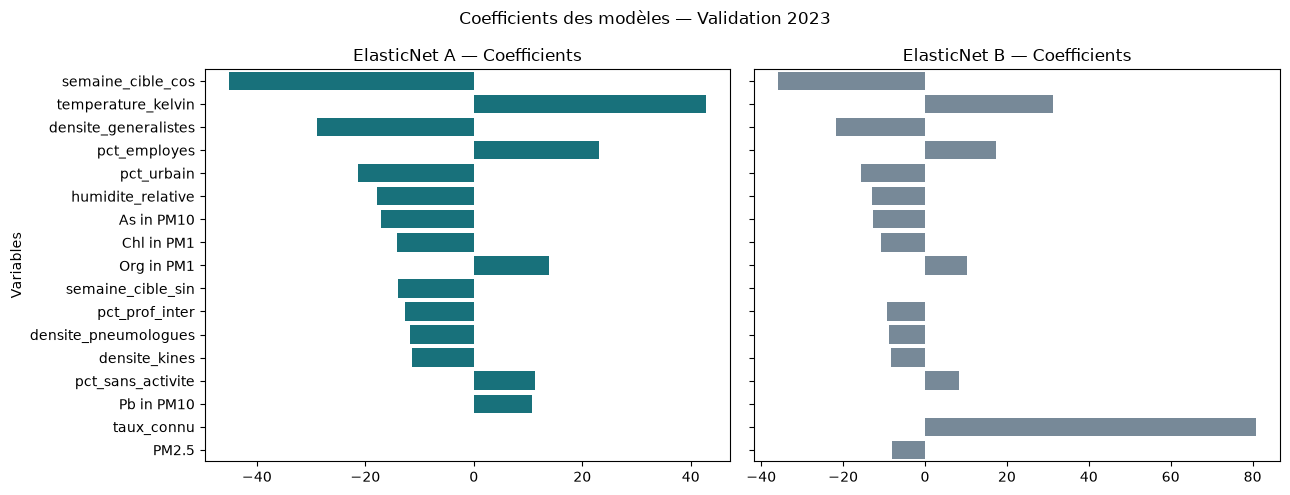

In [33]:
coefficients_A = coefficients_A.round(3)
coefficients_B = coefficients_B.round(3)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

sns.barplot(x = coefficients_A.values , y = coefficients_A.index, color="#087E8B", ax=axes[0], orient = "h")
axes[0].set_title("ElasticNet A — Coefficients") 

sns.barplot(x = coefficients_B.values , y = coefficients_B.index, color="#71899E", ax=axes[1], orient = "h")
axes[1].set_title("ElasticNet B — Coefficients")

for ax in axes:
    ax.set_ylabel("Variables")



fig.suptitle("Coefficients des modèles — Validation 2023")
plt.tight_layout()
plt.show()

### Analyse des coefficients ElasticNet A et B — Validation 2023

La figure présente les variables ayant les coefficients les plus importants dans les deux modèles ElasticNet.

- **Modèle A (sans historique sanitaire) :** les variables les plus influentes sont la température (coefficient positif), l'encodage cyclique de la semaine (`semaine_cible_cos`, négatif) et la densité de médecins généralistes (négatif).
- **Modèle B (avec historique sanitaire) :** `taux_connu` devient la variable dominante (coefficient positif ≈ 81). Les autres variables conservent globalement les mêmes signes, mais leurs coefficients diminuent en valeur absolue.
- **Saisonnalité :** les variables calendaires restent présentes, suggérant une contribution des variations saisonnières à la prédiction.
- **Variables environnementales et territoriales :** plusieurs sont retenues dans les deux modèles, mais leur contribution individuelle apparaît plus faible dans le modèle B.

**Conclusion :** l'ajout du taux sanitaire connu modifie fortement la répartition des coefficients. Le modèle B s'appuie davantage sur l'historique sanitaire, tandis que le modèle A repose principalement sur les variables météorologiques, saisonnières et territoriales.

Cette analyse décrit les associations apprises par les modèles, sans démontrer de relation causale. La comparaison des performances sur 2023 permettra de déterminer si l'ajout du taux connu améliore réellement les prévisions.

## Verifcation / investigation

In [34]:
#je verifie les coeffs non nulls
print("Coefficients non nuls A :", np.sum(modele_A.coef_ != 0))
print("Coefficients non nuls B :", np.sum(modele_B.coef_ != 0))

Coefficients non nuls A : 112
Coefficients non nuls B : 107


In [35]:
#je regarde le coeff pour le taux_connu dans le modele B
coef_B = pd.Series(modele_B.coef_, index=X_train_B.columns)

print("Coefficient taux_connu :", coef_B["taux_connu"])

Coefficient taux_connu : 80.85429389636514


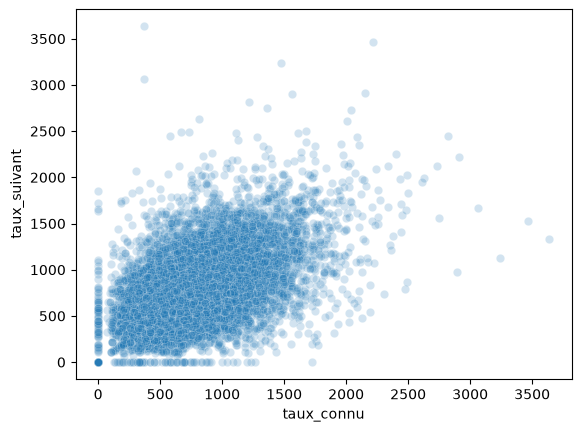

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=data,
    x="taux_connu",
    y="taux_suivant",
    alpha=0.2
)

plt.show()

### Relation entre le taux connu et le taux de la semaine suivante

Chaque point représente une observation correspondant à un couple **semaine–département**.

Une **tendance positive** se dégage : plus le taux sanitaire de la semaine courante (`taux_connu`) est élevé, plus celui de la semaine suivante (`taux_suivant`) tend également à être élevé.

Cependant, une forte variabilité est observée, notamment :
- **`taux_connu = 0` :** le taux de la semaine suivante peut être élevé, indiquant une augmentation soudaine des passages aux urgences.
- **`taux_suivant = 0` :** un taux élevé la semaine précédente peut être suivi d'une chute brutale.

Ces valeurs nulles sont présentes dans les données d'origine et ne résultent pas d'un remplacement des valeurs manquantes.

**Conclusion :** le taux connu apporte une information prédictive, mais ne suffit pas à anticiper les fluctuations hebdomadaires, notamment les hausses et les baisses soudaines.

In [37]:
#compter les observations 0
print("Taux connu = 0 :", (train["taux_connu"] == 0).sum())
print("Taux suivant = 0 :", (train["taux_suivant"] == 0).sum())

print("Taux connu = 0 et suivant > 0 :",
      ((train["taux_connu"] == 0) & (train["taux_suivant"] > 0)).sum())

print("Taux connu > 0 et suivant = 0 :",
      ((train["taux_connu"] > 0) & (train["taux_suivant"] == 0)).sum())

Taux connu = 0 : 45
Taux suivant = 0 : 43
Taux connu = 0 et suivant > 0 : 36
Taux connu > 0 et suivant = 0 : 34


In [38]:
# Comparer correlation pearson vs spearman

#relation linaire
print("Pearson :", train["taux_connu"].corr(
    train["taux_suivant"], method="pearson"))

#co-evolution sans relation parfaitement linaire
print("Spearman :", train["taux_connu"].corr(
    train["taux_suivant"], method="spearman"))

Pearson : 0.5365815075544246
Spearman : 0.5127297090179572


On observere une relation positive lineaire et modere entre le taux_connu et taux_suivante

In [39]:
modele_test = LinearRegression()

modele_test.fit(X_train_B[["taux_connu"]], y_train)

prediction_test = modele_test.predict(X_valid_B[["taux_connu"]])

afficher_scores("Régression taux connu seul", y_valid, prediction_test)

Régression taux connu seul
MAE  : 197.77
RMSE : 269.9
R²   : 0.303


Le taux_connu est informatif : utilisé seul, il explique environ 30 % de la variabilité des taux de 2023.

## 12. Summary of results ElasticNet A & B

,Modèle,MAE,RMSE,R²
0,Persistance,219.03,306.11,0.104
1,Saisonnier,203.92,280.45,0.248
2,ElasticNet A,205.89,276.20,0.271
3,ElasticNet B,190.69,258.09,0.363


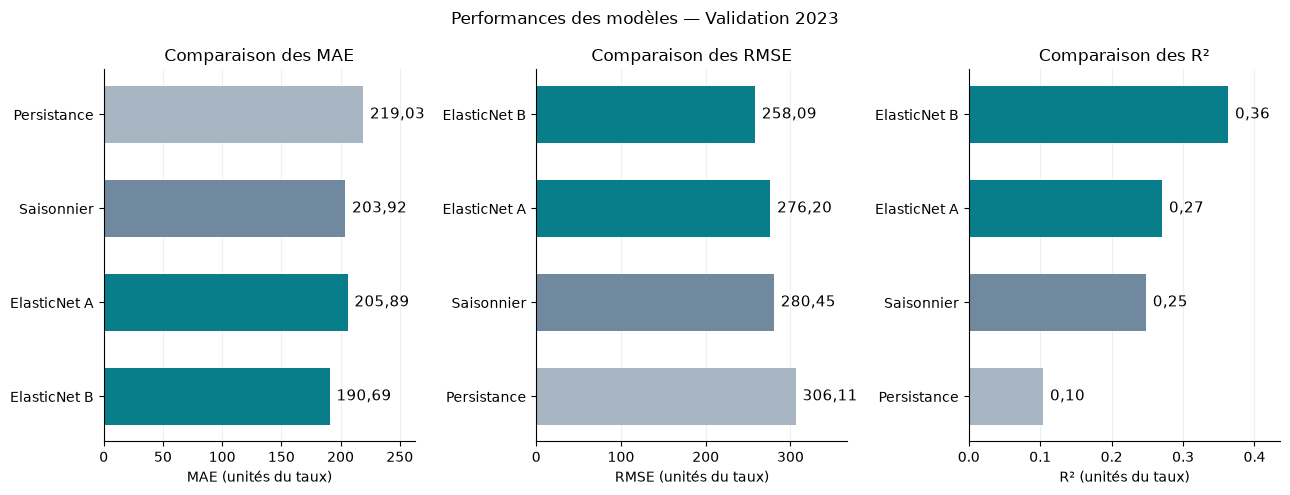

In [40]:
#Summary of results

#calculer les scores per modele
def calculer_scores(nom, reel, prediction):
    return {
        "Modèle": nom,
        "MAE": mean_absolute_error(reel, prediction),
        "RMSE": mean_squared_error(reel, prediction) ** 0.5,
        "R²": r2_score(reel, prediction)
    }

# construction du tableau   

scores = pd.DataFrame([
    calculer_scores("Persistance", y_valid, prediction_persistance),
    calculer_scores("Saisonnier", y_valid, prediction_saisonniere),
    calculer_scores("ElasticNet A", y_valid, prediction_A_baseline),
    calculer_scores("ElasticNet B", y_valid, prediction_B_baseline)
])

# Affichage arrondi, sans modifier les valeurs conservées
display(scores.round({"MAE": 2, "RMSE": 2, "R²": 3}))

#barplot
metrique = "MAE"  # ou "RMSE" ou "R2"
couleurs = ["#A8B5C2", "#71899E", "#087E8B", "#087E8B"]


fig, axes = plt.subplots(1, 3, figsize=(13, 5))

for ax, metrique in zip(axes, ["MAE", "RMSE", "R²"]):
    barres = ax.barh(
        scores["Modèle"],
        scores[metrique],
        color=couleurs,
        height=0.6
    )

    ax.bar_label(
        barres,
        labels=[
            f"{valeur:.2f}".replace(".", ",")
            for valeur in scores[metrique]
        ],
        padding=5,
        fontsize=11
    )

    ax.set_title(f"Comparaison des {metrique}")
    ax.set_xlabel(f"{metrique} (unités du taux)")

    maximum = scores[metrique].max()
    ax.set_xlim(0, maximum * 1.20 if maximum > 0 else 1)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

# Premier modèle en haut ; l'axe est partagé entre les deux graphiques
axes[0].invert_yaxis()

fig.suptitle("Performances des modèles — Validation 2023")
plt.tight_layout()
plt.show()

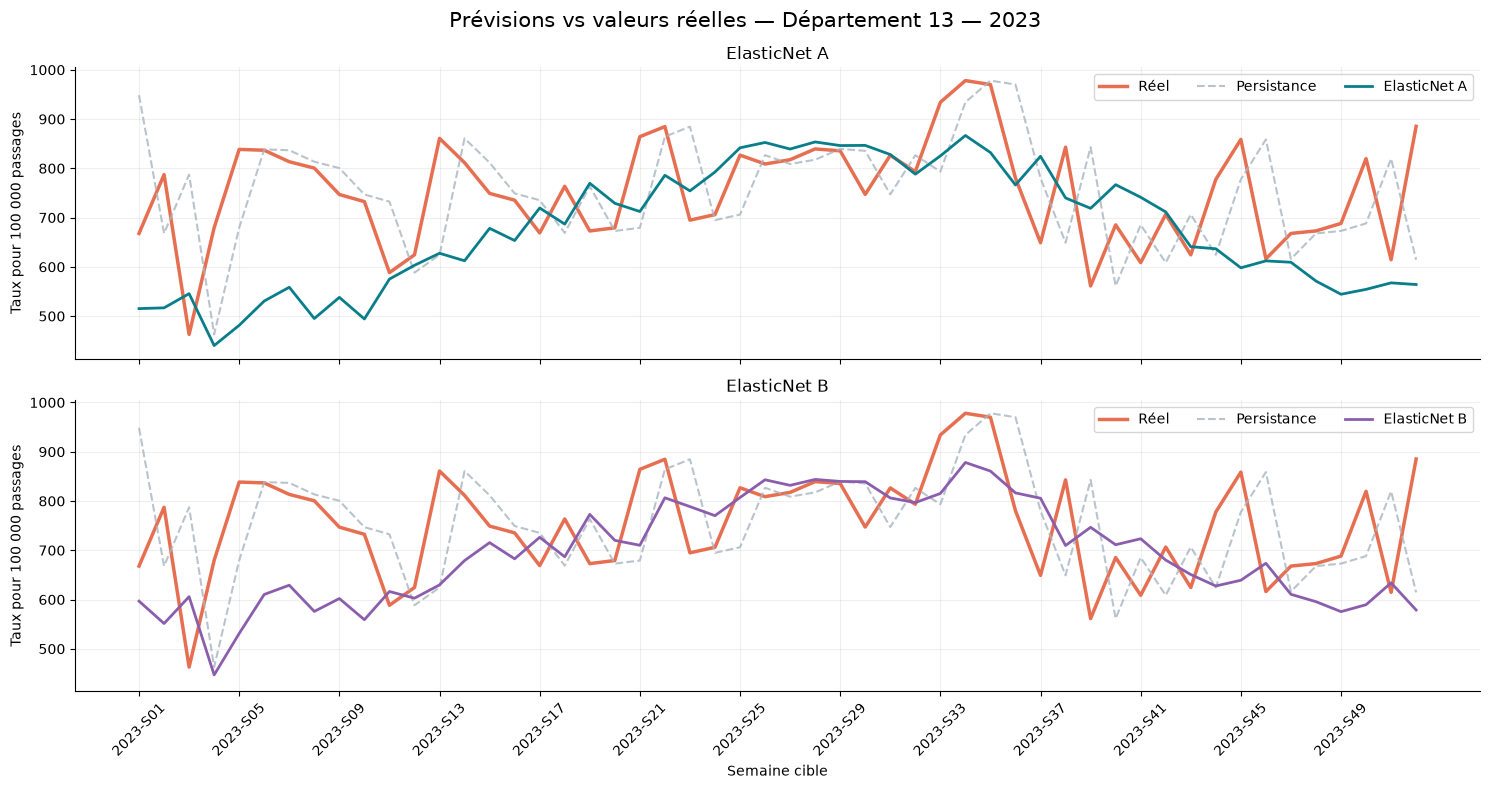

In [41]:

# Comparaison réel vs prédictions

# Choisir le département
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Taux_precedent"] = valid["taux_connu"]
comparaison["Réel (taux_suivant)"] = y_valid
comparaison["Persistance"] = prediction_persistance
comparaison["ElasticNet A"] = prediction_A_baseline
comparaison["ElasticNet B"] = prediction_B_baseline

# Filtrer le département et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")

# Deux graphiques superposés
fig, axes = plt.subplots(
    2, 1, figsize=(15, 8),
    sharex=True, sharey=True
)

modeles = [
    ("ElasticNet A", "#087E8B"),
    ("ElasticNet B", "#8B5EAD")
]

for ax, (modele, couleur) in zip(axes, modeles):

    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Réel (taux_suivant)"],
        label="Réel",
        color="#E76F51",
        linewidth=2.5
    )

    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Persistance"],
        label="Persistance",
        color="#A8B5C2",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8
    )

    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes[modele],
        label=modele,
        color=couleur,
        linewidth=2
    )

    ax.set_title(modele)
    ax.set_ylabel("Taux pour 100 000 passages")
    ax.legend(loc="upper right", ncol=3)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

# Afficher une semaine sur quatre
semaines = courbes["semaine_a_prevoir"].iloc[::4]

axes[-1].set_xticks(semaines)
axes[-1].tick_params(axis="x", rotation=45)
axes[-1].set_xlabel("Semaine cible")

fig.suptitle(
    f"Prévisions vs valeurs réelles — Département {dept} — 2023",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [42]:
#Verification des decalages
colonnes = [
    "semaine_a_prevoir",
    "Réel (taux_suivant)",
    "Persistance",
    "ElasticNet A",
    "ElasticNet B"
]

display(courbes[colonnes].round(2))

,semaine_a_prevoir,Réel (taux_suivant),Persistance,ElasticNet A,ElasticNet B
9900,2023-S01,667.91,948.49,515.27,596.77
9996,2023-S02,787.24,667.91,516.80,551.33
10092,2023-S03,462.82,787.24,545.59,605.81
10188,2023-S04,679.48,462.82,440.23,446.96
10284,2023-S05,838.44,679.48,481.34,531.10
10380,2023-S06,836.75,838.44,530.65,610.34
10476,2023-S07,813.38,836.75,558.60,629.08
10572,2023-S08,800.46,813.38,495.12,575.83
10668,2023-S09,746.91,800.46,538.11,602.00
10764,2023-S10,732.44,746.91,494.23,558.99


on observe:
1. un décalage d'une semaine dans la prediction
2. le modele lisse les pics - pas adapté dans ce forme aux changements rapides

### Investigation "décalage"

In [43]:
#correlation avec la cible (taux connu) avec taux à predire (taux_suivant dans y_train)
print("Corrélation avec la cible :",
      X_train_B["taux_connu"].corr(y_train))

#correlation avec la cible (taux connu) avec taux à predire (taux_suivant dans y_valid)
print("Corrélation avec la cible :",
      X_valid_B["taux_connu"].corr(y_valid))

#correlation avec la cible (taux connu) avec taux predit sur validation par modele B
pred = pd.Series(
    np.asarray(prediction_B_baseline).ravel(),
    index=X_valid_B.index
)

print(
    "Corrélation avec le taux connu :",
    X_valid_B["taux_connu"].corr(pred)
)


Corrélation avec la cible : 0.5365815075544245
Corrélation avec la cible : 0.5511592848605407
Corrélation avec le taux connu : 0.847111772777436


In [44]:
# Comparaison des corrélations temporelles par département: Pour chaque département, 
# nous calculons les corrélations de deux modèles avec cinq décalages différents.

resultats = []

for dept, groupe in comparaison.groupby("code_dept"):
    groupe = groupe.sort_values("semaine_a_prevoir")

    for modele in ["ElasticNet A", "ElasticNet B"]:
        for decalage in [-2, -1, 0, 1, 2]:

            corr = groupe[modele].corr(
                groupe["Réel (taux_suivant)"].shift(decalage)
            )

            resultats.append({
                "departement": dept,
                "modele": modele,
                "decalage": decalage,
                "correlation": corr
            })

df_corr = pd.DataFrame(resultats)

# Moyenne des corrélations sur tous les départements
resume = df_corr.groupby(
    ["modele", "decalage"]
)["correlation"].mean().unstack(0)

print(resume.round(3))

modele    ElasticNet A  ElasticNet B
decalage                            
-2               0.500         0.476
-1               0.522         0.515
 0               0.546         0.539
 1               0.561         0.825
 2               0.542         0.534


Decalage = 0  compare la prevision avec le reel S+1 0.539 pour B, 
decalage = 1  compare la prevision avec le réel de S 0.8.25 pour B

Le modele B suit surtout le taux courant de la semaine S

# C. OPTIMISATION DES HYPERPARAMETRES

## 13. Optimisation des hyperparametres avec GridSearchCV


Validation croisée temporelle pour l'optimisation avec GridSearchCV

Une validation croisée classique n'est pas adaptée à nos données temporelles : elle pourrait entraîner le modèle sur des observations de 2022 et l'évaluer sur celles de 2021, introduisant ainsi une fuite d'information temporelle.

1. Création de folds temporels

TimeSeriesSplit respecte la chronologie : le modèle apprend sur le passé pour prédire le futur.

Cependant, cette méthode repose sur l'ordre des lignes et non sur les dates. Or, notre jeu de données contient plusieurs départements pour chaque semaine.

Nous créons donc des folds temporels personnalisés afin de :

Conserver toutes les observations d'une même semaine (tous départements confondus) dans le même fold.

Garantir que les semaines d'entraînement précèdent toujours celles de validation.

Évaluer les différentes combinaisons d'hyperparamètres sans mélange temporel.

2. Prévention des fuites de données lors du prétraitement

Une standardisation calculée sur l'ensemble du jeu d'entraînement avant la validation croisée introduirait une fuite d'information entre les folds.

Nous utilisons donc un Pipeline intégrant le prétraitement et le modèle ElasticNet.

À chaque fold, les paramètres de standardisation sont calculés uniquement sur les données d'entraînement, puis appliqués aux données de validation.

Objectif : optimiser les hyperparamètres avec GridSearchCV tout en garantissant une évaluation chronologiquement cohérente et sans fuite de données.

### 13.a. Preparation des données

In [57]:
# Je repars sur data et la separation des données

data = data.copy()

# je fais le trie par anné, semaine, departement
data = data.sort_values(
    ["annee_cible", "semaine_cible", "code_dept"]
).reset_index(drop=True)


#separation train - valid - test
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")



Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


In [60]:
#Train-test split (X, y) et preparation set A et set B

#colonnes à exclure: date_semaine, semaine_a_prevoir, TousAge_allergie_urgences, "semaine_cos", "semaine_sin" 
# (semaine_cos, semaine_sin sont supprimées pour eviter la multicolinéarité)
exclure_X = [
    "taux_suivant",
    "date_semaine",
    "semaine_a_prevoir",
    "TousAge_allergie_urgences",
   "semaine_cos", "semaine_sin"
]

#Separation X, y A et B
X_train_B = train.drop(columns=exclure_X)
X_valid_B = valid.drop(columns=exclure_X)
X_test_B = test.drop(columns=exclure_X)

X_train_A = X_train_B.drop(columns="taux_connu")
X_valid_A = X_valid_B.drop(columns="taux_connu")
X_test_A = X_test_B.drop(columns="taux_connu")

y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]

In [61]:
print(X_train_B.shape, X_valid_B.shape, X_test_B.shape)

(9888, 57) (4992, 57) (4992, 57)


In [47]:
X_train_B.info()

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Data columns (total 57 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   code_dept                                   9888 non-null   str    
 1   As in PM10                                  9888 non-null   float64
 2   BaP in PM10                                 9888 non-null   float64
 3   Cd in PM10                                  9888 non-null   float64
 4   Ni in PM10                                  9888 non-null   float64
 5   Pb in PM10                                  9888 non-null   float64
 6   NO2                                         9888 non-null   float64
 7   O3                                          9888 non-null   float64
 8   PM10                                        9888 non-null   float64
 9   PM2.5                                       9888 non-null   float64
 10  SO2                    

In [31]:

#definition de la fonction de preprocessing pour les colonnes numeriques et categorielle (standardisation et encodage)

def creer_preprocessing(X):

# Colonnes numériques
    numeriques = X.select_dtypes(include="number").columns

# Colonnes à ne pas standardiser
    exclure = [
        "annee", "semaine",
        "tp_tempete_poussiere_chasse_neige",
        "annee_cible", "semaine_cible"
    ]

# Ajouter les colonnes binaires (0/1)
    exclure += [
        col for col in numeriques
        if X_train[col].dropna().isin([0, 1]).all()
    ]
# Conserver les variables à standardiser
    variables_scaler = [col for col in numeriques if col not in exclure]

# Variables conservées sans transformation
    variables_autres = [
        col for col in X_train_B.columns
        if col not in variables_scaler + ["code_dept"]
    ]

    return ColumnTransformer(
        transformers=[
            ("scaler", StandardScaler(), variables_scaler),
            ("encoder", OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ), ["code_dept"])
        ],
        remainder="passthrough"
    )


print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())
print("Colonnes à standardiser :", variables_scaler)
print("Colonnes  exclues de standardisation :", exclure)



Nombre de colonnes numériques : 153
Colonnes numériques : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergolo

### 13.b. Fold Temporelle

In [49]:
#Creation de fold temporelle pour crossvalidation

folds_temporels = []

for debut, fin in [(1, 13), (14, 26), (27, 39), (40, 53)]:  #4 periodes de validation

    idx_train = np.where(
        (train["annee_cible"] == 2021) |
        ((train["annee_cible"] == 2022) &
         (train["semaine_cible"] < debut))
    )[0]

    idx_valid = np.where(
        (train["annee_cible"] == 2022) &
        (train["semaine_cible"].between(debut, fin))
    )[0]

    folds_temporels.append((idx_train, idx_valid))

In [50]:
#verification des folds
for i, (idx_train, idx_valid) in enumerate(folds_temporels, 1):

    print(f"\nFold {i}")

    print("Train :", len(idx_train), "observations")
    print("Valid :", len(idx_valid), "observations")

    print("Années train :",
          train.iloc[idx_train]["annee_cible"].unique())

    print("Semaines validation :",
          train.iloc[idx_valid]["semaine_cible"].min(),
          "à",
          train.iloc[idx_valid]["semaine_cible"].max())


Fold 1
Train : 4896 observations
Valid : 1248 observations
Années train : [2021]
Semaines validation : 1 à 13

Fold 2
Train : 6144 observations
Valid : 1248 observations
Années train : [2021 2022]
Semaines validation : 14 à 26

Fold 3
Train : 7392 observations
Valid : 1248 observations
Années train : [2021 2022]
Semaines validation : 27 à 39

Fold 4
Train : 8640 observations
Valid : 1248 observations
Années train : [2021 2022]
Semaines validation : 40 à 52


### 13.c. GridSearchCV

In [51]:
from sklearn.model_selection import GridSearchCV

parameters = {
    "modele__alpha": [0.001, 0.01, 0.1, 1, 10],
    "modele__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
}

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

def optimiser_elasticnet(X, y):

    pipeline = Pipeline([
        ("preprocessing", creer_preprocessing(X)),
        ("modele", ElasticNet(max_iter=10000))
    ])

    grid=GridSearchCV(
        estimator = pipeline,
        param_grid = parameters,
        cv = folds_temporels,
        scoring = scoring,
        n_jobs = -1,
        refit = "MAE",
    )
    grid.fit(X, y)  

    return grid

# Optimisation des deux modèles
grid_A = optimiser_elasticnet(X_train_A, y_train)
grid_B = optimiser_elasticnet(X_train_B, y_train)


#Resultats
print("Meilleur parametres modele A:", grid_A.best_params_)
print("Meilleur score modele A:", grid_A.best_score_)

print("Meilleurs paramètres B :", grid_B.best_params_)
print("Meilleure MAE B :", grid_B.best_score_)





Meilleur parametres modele A: {'modele__alpha': 0.01, 'modele__l1_ratio': 0.5}
Meilleur score modele A: -194.61546987448713
Meilleurs paramètres B : {'modele__alpha': 0.01, 'modele__l1_ratio': 0.1}
Meilleure MAE B : -181.7784923365941


In [52]:
prediction_A_opt = grid_A.predict(X_valid_A)
prediction_B_opt = grid_B.predict(X_valid_B)

afficher_scores("ElasticNet A optimisé", y_valid, prediction_A_opt)
afficher_scores("ElasticNet B optimisé", y_valid, prediction_B_opt)

ElasticNet A optimisé
MAE  : 186.06
RMSE : 251.76
R²   : 0.394
ElasticNet B optimisé
MAE  : 179.19
RMSE : 245.16
R²   : 0.425


### 13.d. Comparision des resultats

In [53]:
#tableau comparatif des scores de 6 modeles sur validation 2023

scores_baseline = scores.copy()


scores_optimises_Grid = pd.DataFrame([
    calculer_scores("ElasticNet A optimisé", y_valid, prediction_A_opt),
    calculer_scores("ElasticNet B optimisé", y_valid, prediction_B_opt)
])

scores_comparaison_Grid = pd.concat(
    [scores_baseline, scores_optimises_Grid],
    ignore_index=True
)

display(scores_comparaison_Grid.round(3))


,Modèle,MAE,RMSE,R²
0,Persistance,219.028,306.108,0.104
1,Saisonnier,203.921,280.451,0.248
2,ElasticNet A,205.894,276.197,0.271
3,ElasticNet B,190.691,258.092,0.363
4,ElasticNet A optimisé,186.062,251.763,0.394
5,ElasticNet B optimisé,179.187,245.163,0.425


In [54]:
scores_comparaison_Grid = scores_comparaison_Grid.sort_values("MAE").reset_index(drop=True)

display(scores_comparaison_Grid.round(3))

,Modèle,MAE,RMSE,R²
0,ElasticNet B optimisé,179.187,245.163,0.425
1,ElasticNet A optimisé,186.062,251.763,0.394
2,ElasticNet B,190.691,258.092,0.363
3,Saisonnier,203.921,280.451,0.248
4,ElasticNet A,205.894,276.197,0.271
5,Persistance,219.028,306.108,0.104


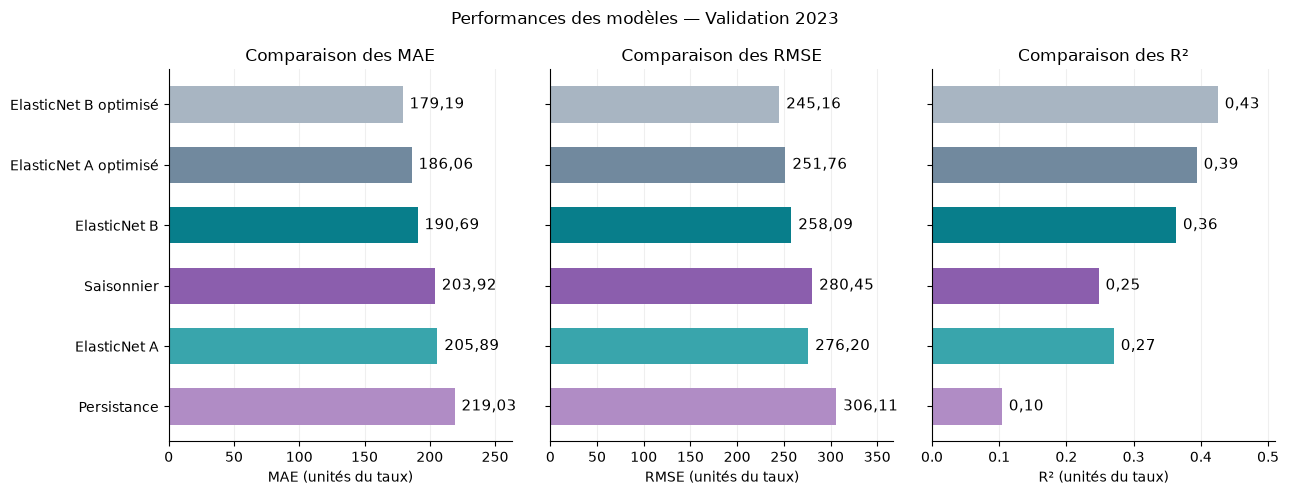

In [55]:
#barplot
metriques = ["MAE", "RMSE", "R²"]

couleurs = [
    "#A8B5C2", "#71899E",
    "#087E8B", "#8B5EAD",
    "#39A5AC", "#B08CC5"]


fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, metrique in zip(axes, ["MAE", "RMSE", "R²"]):
    barres = ax.barh(
        scores_comparaison_Grid["Modèle"],
        scores_comparaison_Grid[metrique],
        color=couleurs,
        height=0.6
    )

    ax.bar_label(
        barres,
        labels=[
            f"{valeur:.2f}".replace(".", ",")
            for valeur in scores_comparaison_Grid[metrique]
        ],
        padding=5,
        fontsize=11
    )

    ax.set_title(f"Comparaison des {metrique}")
    ax.set_xlabel(f"{metrique} (unités du taux)")

    maximum = scores_comparaison_Grid[metrique].max()
    ax.set_xlim(0, maximum * 1.20 if maximum > 0 else 1)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

# Premier modèle en haut ; l'axe est partagé entre les deux graphiques
axes[0].invert_yaxis()

fig.suptitle("Performances des modèles — Validation 2023")
plt.tight_layout()
plt.show()

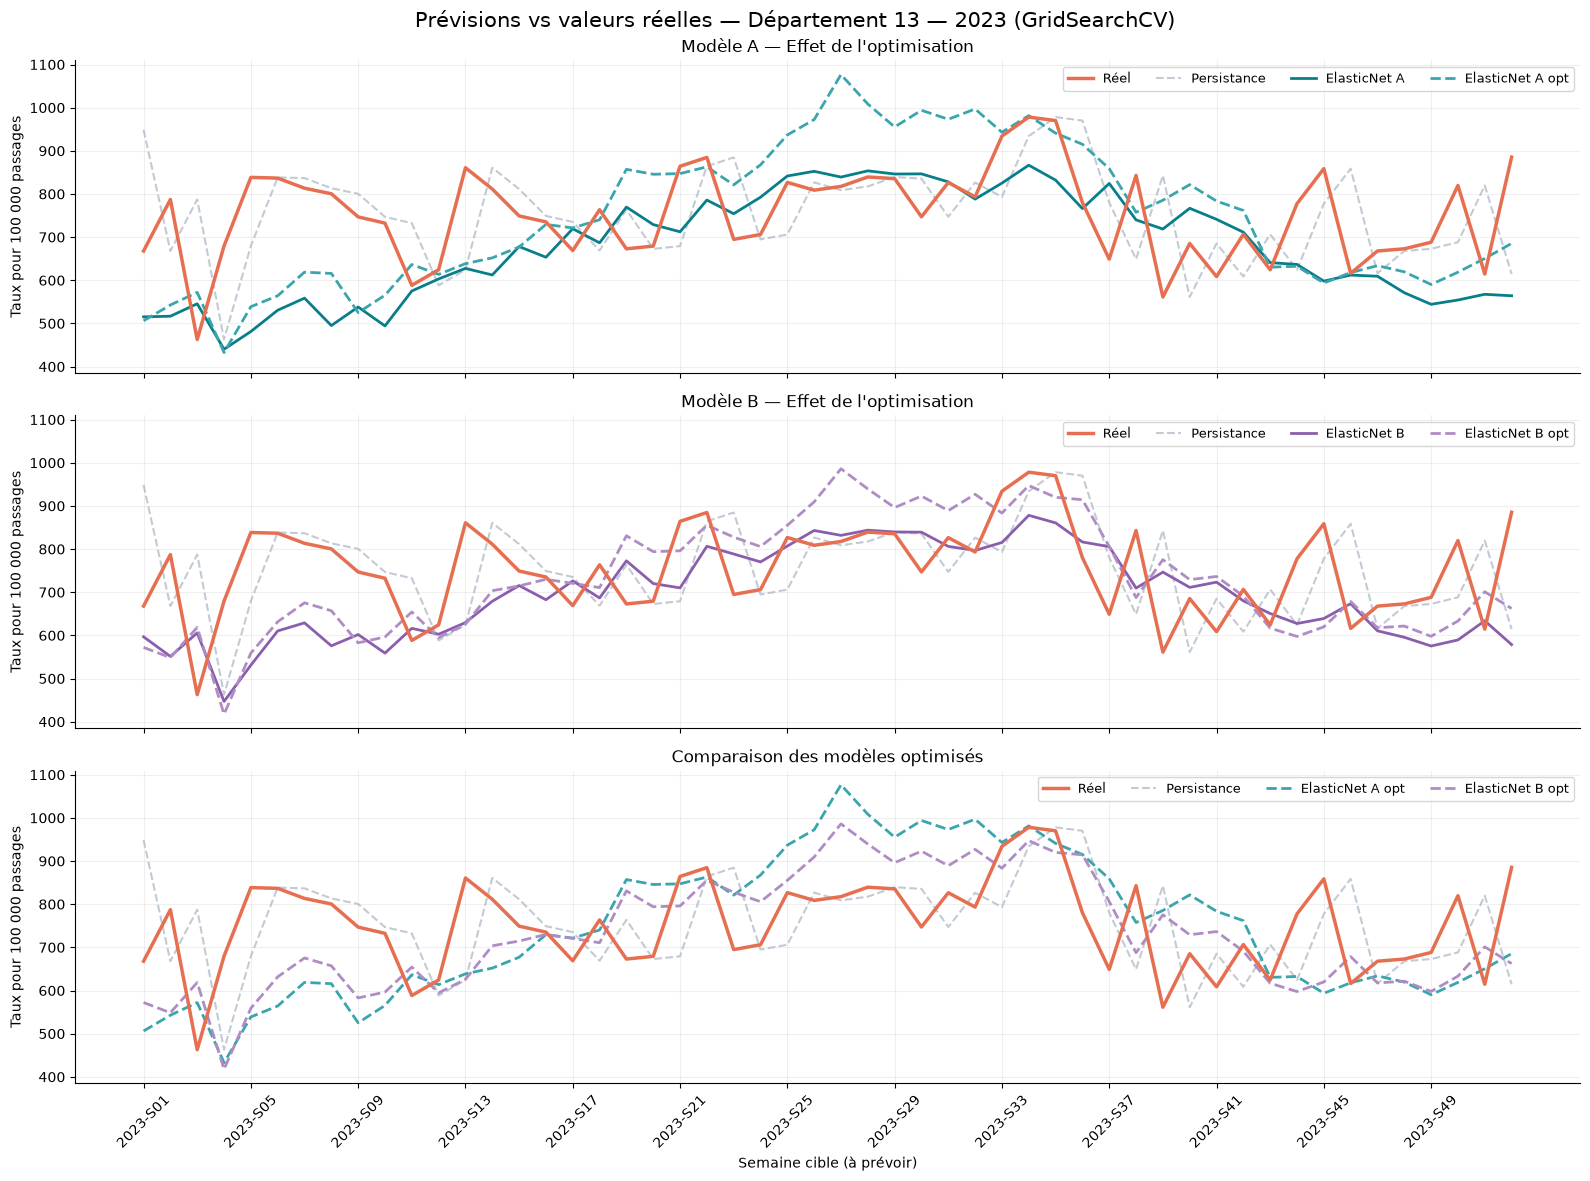

In [70]:

# Comparaison réel vs prédictions

# Choisir le département
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Réel"] = y_valid
comparaison["Persistance"] = prediction_persistance
comparaison["ElasticNet A"] = prediction_A_baseline
comparaison["ElasticNet B"] = prediction_B_baseline
comparaison["ElasticNet A opt"] = prediction_A_opt
comparaison["ElasticNet B opt"] = prediction_B_opt

# Filtrer et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")

# Configuration des graphiques
groupes = [
    (["ElasticNet A", "ElasticNet A opt"],
     "Modèle A — Effet de l'optimisation"),

    (["ElasticNet B", "ElasticNet B opt"],
     "Modèle B — Effet de l'optimisation"),

    (["ElasticNet A opt", "ElasticNet B opt"],
     "Comparaison des modèles optimisés")
]

couleurs = {
    "ElasticNet A": "#087E8B",
    "ElasticNet A opt": "#39A5AC",
    "ElasticNet B": "#8B5EAD",
    "ElasticNet B opt": "#B08CC5"
}

fig, axes = plt.subplots(
    3, 1, figsize=(16, 12),
    sharex=True, sharey=True
)

for ax, (modeles, titre) in zip(axes, groupes):

    # Valeurs réelles
    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Réel"],
        label="Réel",
        color="#E76F51",
        linewidth=2.5,
        zorder=3
    )

    # Baseline de persistance
    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Persistance"],
        label="Persistance",
        color="#A8B5C2",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7
    )

    # Modèles à comparer
    for modele in modeles:
        ax.plot(
            courbes["semaine_a_prevoir"],
            courbes[modele],
            label=modele,
            color=couleurs[modele],
            linewidth=2,
            linestyle="--" if "opt" in modele else "-"
        )

    ax.set_title(titre, fontsize=12)
    ax.set_ylabel("Taux pour 100 000 passages")
    ax.legend(loc="upper right", ncol=4, fontsize=9)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

# Afficher une semaine sur quatre
semaines = courbes["semaine_a_prevoir"].iloc[::4]

axes[-1].set_xticks(semaines)
axes[-1].tick_params(axis="x", rotation=45)
axes[-1].set_xlabel("Semaine cible (à prévoir)")

fig.suptitle(
    f"Prévisions vs valeurs réelles — Département {dept} — 2023 (GridSearchCV)",
    fontsize=15
)

plt.tight_layout()
plt.show()


# 14.OPTUNA

In [57]:
# À exécuter une seule fois si nécessaire
%pip install optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import optuna

In [59]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

def optimiser_optuna(X, y, n_trials=50):

    def objectif(trial):
# Hyperparamètres proposés par Optuna
        alpha = trial.suggest_float("alpha", 0.001, 10.0, log=True)
        l1_ratio = trial.suggest_float("l1_ratio", 0.1, 1.0)
#Pipeline avec prétraitement et modèle ElasticNet
        pipeline = Pipeline([
            ("preprocessing", creer_preprocessing(X)),
            ("modele", ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000))
        ])

#Validation croisée temporelle pour évaluer la performance
        scores = cross_validate(
            pipeline, X, y,
            cv=folds_temporels,
            scoring = scoring,
            n_jobs = -1)

        # Enregistrer les autres métriques
        trial.set_user_attr("RMSE", -scores["test_RMSE"].mean())
        trial.set_user_attr("R2", scores["test_R2"].mean())
            
        return -scores["test_MAE"].mean() # MAE positive à minimiser

#Lancer l'optimisation avec Optuna
    etude = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
    )
    etude.optimize(objectif, n_trials=n_trials)

    return etude

In [60]:
#Optimiser les deux modèles avec Optuna

study_A = optimiser_optuna(X_train_A, y_train)
study_B = optimiser_optuna(X_train_B, y_train)

print("Meilleurs paramètres A :", study_A.best_params)
print("Meilleure MAE A :", study_A.best_value)

print("Meilleurs paramètres B :", study_B.best_params)
print("Meilleure MAE B :", study_B.best_value)

[I 2026-11-10 11:46:22,537] A new study created in memory with name: no-name-554a10c1-663b-43c9-ae67-660345dc3c8a
[I 2026-11-10 11:46:24,620] Trial 0 finished with value: 195.10908629181765 and parameters: {'alpha': 0.03148911647956861, 'l1_ratio': 0.9556428757689246}. Best is trial 0 with value: 195.10908629181765.
[I 2026-11-10 11:46:25,292] Trial 1 finished with value: 206.53689066046275 and parameters: {'alpha': 0.8471801418819978, 'l1_ratio': 0.6387926357773329}. Best is trial 0 with value: 195.10908629181765.
[I 2026-11-10 11:46:35,102] Trial 2 finished with value: 194.59703034278107 and parameters: {'alpha': 0.004207988669606638, 'l1_ratio': 0.2403950683025824}. Best is trial 2 with value: 194.59703034278107.
[I 2026-11-10 11:46:57,363] Trial 3 finished with value: 196.17058725980988 and parameters: {'alpha': 0.0017073967431528124, 'l1_ratio': 0.8795585311974417}. Best is trial 2 with value: 194.59703034278107.
[I 2026-11-10 11:46:57,971] Trial 4 finished with value: 201.5793534

Meilleurs paramètres A : {'alpha': 0.005550261626307071, 'l1_ratio': 0.2180808024087491}
Meilleure MAE A : 194.48953649779727
Meilleurs paramètres B : {'alpha': 0.009872852304987833, 'l1_ratio': 0.1313572883792616}
Meilleure MAE B : 181.775615472504


In [61]:
# Modèle A
modele_A_optuna = Pipeline([
    ("preprocessing", creer_preprocessing(X_train_A)),
    ("modele", ElasticNet(
        **study_A.best_params,
        max_iter=10000
    ))
])

modele_A_optuna.fit(X_train_A, y_train)
prediction_A_optuna = modele_A_optuna.predict(X_valid_A)


# Modèle B
modele_B_optuna = Pipeline([
    ("preprocessing", creer_preprocessing(X_train_B)),
    ("modele", ElasticNet(
        **study_B.best_params,
        max_iter=10000
    ))
])

modele_B_optuna.fit(X_train_B, y_train)
prediction_B_optuna = modele_B_optuna.predict(X_valid_B)

In [62]:
afficher_scores("ElasticNet A — Optuna", y_valid, prediction_A_optuna)
afficher_scores("ElasticNet B — Optuna", y_valid, prediction_B_optuna)

ElasticNet A — Optuna
MAE  : 185.64
RMSE : 251.27
R²   : 0.396
ElasticNet B — Optuna
MAE  : 179.08
RMSE : 245.03
R²   : 0.426


In [63]:
#tableau comparatif des scores de 6 modeles sur validation 2023


scores_optuna = pd.DataFrame([
    calculer_scores("ElasticNet A Optuna", y_valid, prediction_A_optuna),
    calculer_scores("ElasticNet B Optuna", y_valid, prediction_B_optuna)
])

scores_comparaison_optuna = pd.concat(
    [scores_comparaison_Grid, scores_optuna],
    ignore_index=True
)

display(scores_comparaison_optuna.round(3))



,Modèle,MAE,RMSE,R²
0,ElasticNet B optimisé,179.187,245.163,0.425
1,ElasticNet A optimisé,186.062,251.763,0.394
2,ElasticNet B,190.691,258.092,0.363
3,Saisonnier,203.921,280.451,0.248
4,ElasticNet A,205.894,276.197,0.271
5,Persistance,219.028,306.108,0.104
6,ElasticNet A Optuna,185.640,251.273,0.396
7,ElasticNet B Optuna,179.085,245.028,0.426


In [64]:
scores_comparaison_optuna = scores_comparaison_optuna.sort_values("R²", ascending=False).round(3)

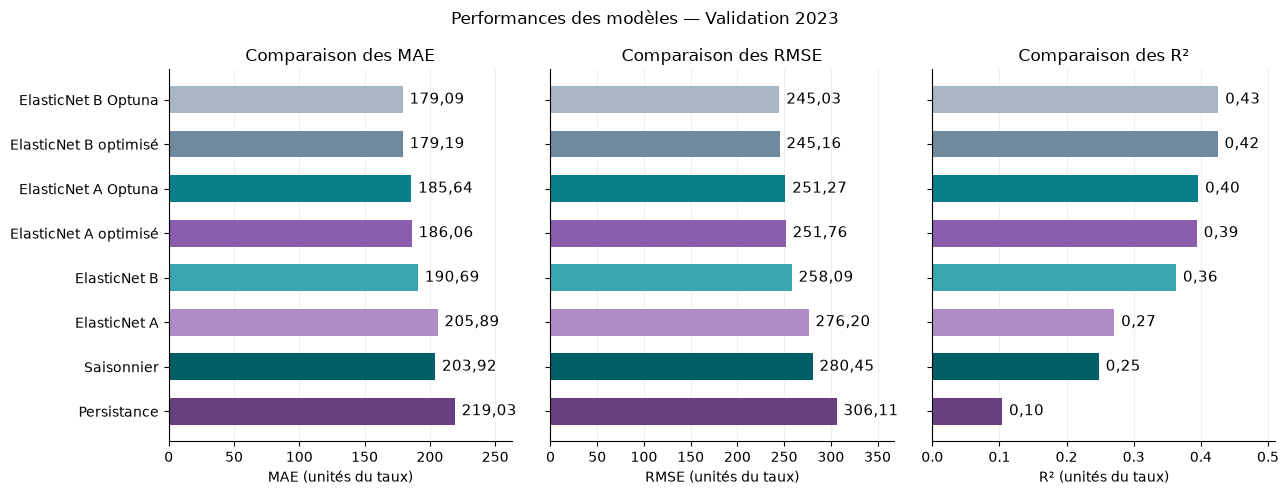

In [65]:
#barplot
metriques = ["MAE", "RMSE", "R²"]

couleurs = [
    "#A8B5C2", "#71899E",
    "#087E8B", "#8B5EAD",
    "#39A5AC", "#B08CC5",
    "#005F66" , "#684080"]


fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, metrique in zip(axes, ["MAE", "RMSE", "R²"]):
    barres = ax.barh(
        scores_comparaison_optuna["Modèle"],
        scores_comparaison_optuna[metrique],
        color=couleurs,
        height=0.6
    )

    ax.bar_label(
        barres,
        labels=[
            f"{valeur:.2f}".replace(".", ",")
            for valeur in scores_comparaison_optuna[metrique]
        ],
        padding=5,
        fontsize=11
    )

    ax.set_title(f"Comparaison des {metrique}")
    ax.set_xlabel(f"{metrique} (unités du taux)")

    maximum = scores_comparaison_optuna[metrique].max()
    ax.set_xlim(0, maximum * 1.20 if maximum > 0 else 1)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

# Premier modèle en haut ; l'axe est partagé entre les deux graphiques
axes[0].invert_yaxis()

fig.suptitle("Performances des modèles — Validation 2023")
plt.tight_layout()
plt.show()

In [66]:
print("Modèle A :", study_A.best_trial.number)
print("Modèle B :", study_B.best_trial.number)

Modèle A : 48
Modèle B : 43


In [67]:
#Visualisation des résultats d'Optuna
# Évolution de la MAE au fil des essais
from plotly.subplots import make_subplots
fig = make_subplots(rows=1, cols=2, 
                    subplot_titles=("ElasticNet A", "ElasticNet B"))

#Recuperation des figures d'Optuna pour chaque modèle
fig_A = optuna.visualization.plot_optimization_history(study_A)
fig_B = optuna.visualization.plot_optimization_history(study_B)

for trace in fig_A.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig_B.data:
    fig.add_trace(trace, row=1, col=2)

fig.update_layout(
    title="Historique d'optimisation Optuna",
    width=1200,
    height=450,
    showlegend=False
)

fig.show()

In [68]:
# Importance des hyperparamètres

fig = make_subplots(rows=1, cols=2, 
                    subplot_titles=("ElasticNet A", "ElasticNet B"))

#Recuperation des figures d'Optuna pour chaque modèle
fig_A = optuna.visualization.plot_param_importances(study_A)
fig_B = optuna.visualization.plot_param_importances(study_B)

for trace in fig_A.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig_B.data:
    fig.add_trace(trace, row=1, col=2)

fig.update_layout(
    title="Importance des hyperparamètres Optuna",
    width=1200,
    height=450,
    showlegend=False
)

fig.show()

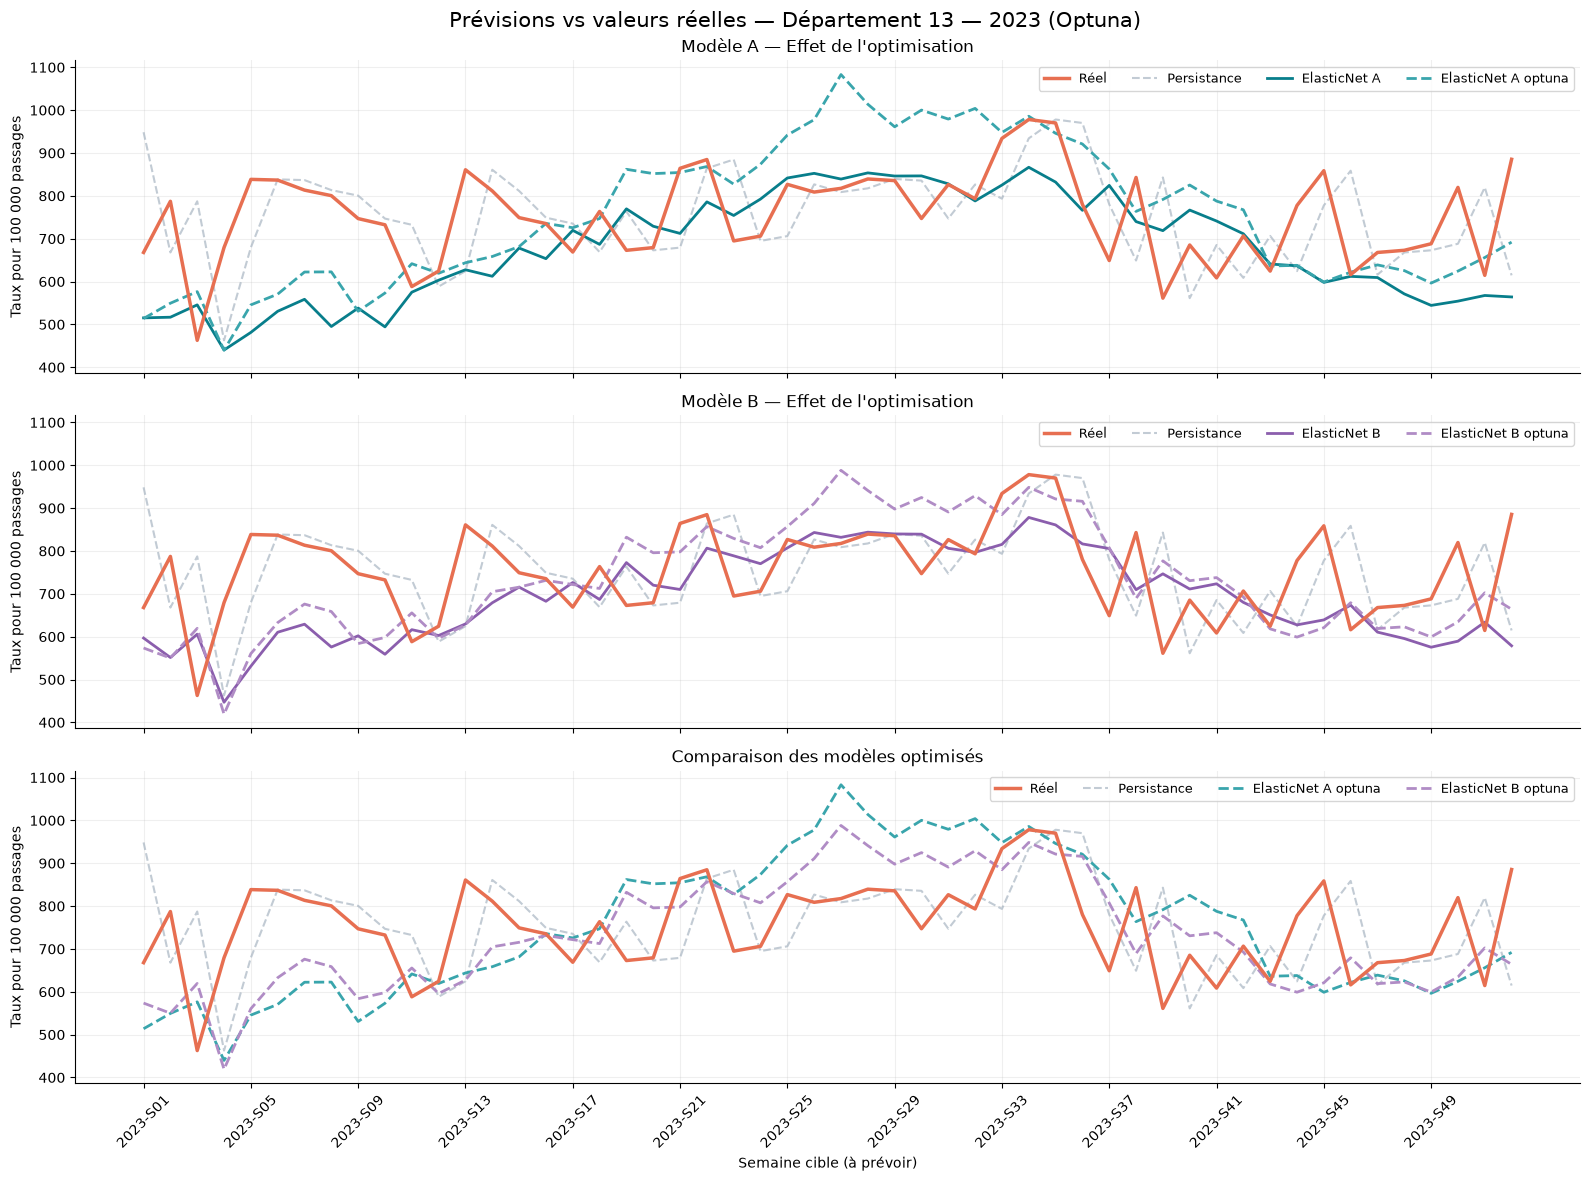

In [71]:

# Comparaison réel vs prédictions

# Choisir le département
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Réel"] = y_valid
comparaison["Persistance"] = prediction_persistance
comparaison["ElasticNet A"] = prediction_A_baseline
comparaison["ElasticNet B"] = prediction_B_baseline
comparaison["ElasticNet A optuna"] = prediction_A_optuna
comparaison["ElasticNet B optuna"] = prediction_B_optuna

# Filtrer et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")

# Configuration des graphiques
groupes = [
    (["ElasticNet A", "ElasticNet A optuna"],
     "Modèle A — Effet de l'optimisation"),

    (["ElasticNet B", "ElasticNet B optuna"],
     "Modèle B — Effet de l'optimisation"),

    (["ElasticNet A optuna", "ElasticNet B optuna"],
     "Comparaison des modèles optimisés")
]

couleurs = {
    "ElasticNet A": "#087E8B",
    "ElasticNet A optuna": "#39A5AC",
    "ElasticNet B": "#8B5EAD",
    "ElasticNet B optuna": "#B08CC5"
}

fig, axes = plt.subplots(
    3, 1, figsize=(16, 12),
    sharex=True, sharey=True
)

for ax, (modeles, titre) in zip(axes, groupes):

    # Valeurs réelles
    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Réel"],
        label="Réel",
        color="#E76F51",
        linewidth=2.5,
        zorder=3
    )

    # Baseline de persistance
    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Persistance"],
        label="Persistance",
        color="#A8B5C2",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7
    )

    # Modèles à comparer
    for modele in modeles:
        ax.plot(
            courbes["semaine_a_prevoir"],
            courbes[modele],
            label=modele,
            color=couleurs[modele],
            linewidth=2,
            linestyle="--" if "opt" in modele else "-"
        )

    ax.set_title(titre, fontsize=12)
    ax.set_ylabel("Taux pour 100 000 passages")
    ax.legend(loc="upper right", ncol=4, fontsize=9)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

# Afficher une semaine sur quatre
semaines = courbes["semaine_a_prevoir"].iloc[::4]

axes[-1].set_xticks(semaines)
axes[-1].tick_params(axis="x", rotation=45)
axes[-1].set_xlabel("Semaine cible (à prévoir)")

fig.suptitle(
    f"Prévisions vs valeurs réelles — Département {dept} — 2023 (Optuna)",
    fontsize=15
)

plt.tight_layout()
plt.show()


15. 

In [80]:
prediction_B_opt_test = grid_B.predict(X_test_B)
prediction_B_optuna_test = modele_B_optuna.predict(X_test_B)

afficher_scores("ElasticNet B GridSearchCV", y_test, prediction_B_opt_test)
afficher_scores("ElasticNet B Optuna", y_test, prediction_B_optuna_test)

ElasticNet B GridSearchCV
MAE  : 173.58
RMSE : 235.29
R²   : 0.355
ElasticNet B Optuna
MAE  : 173.49
RMSE : 235.17
R²   : 0.356


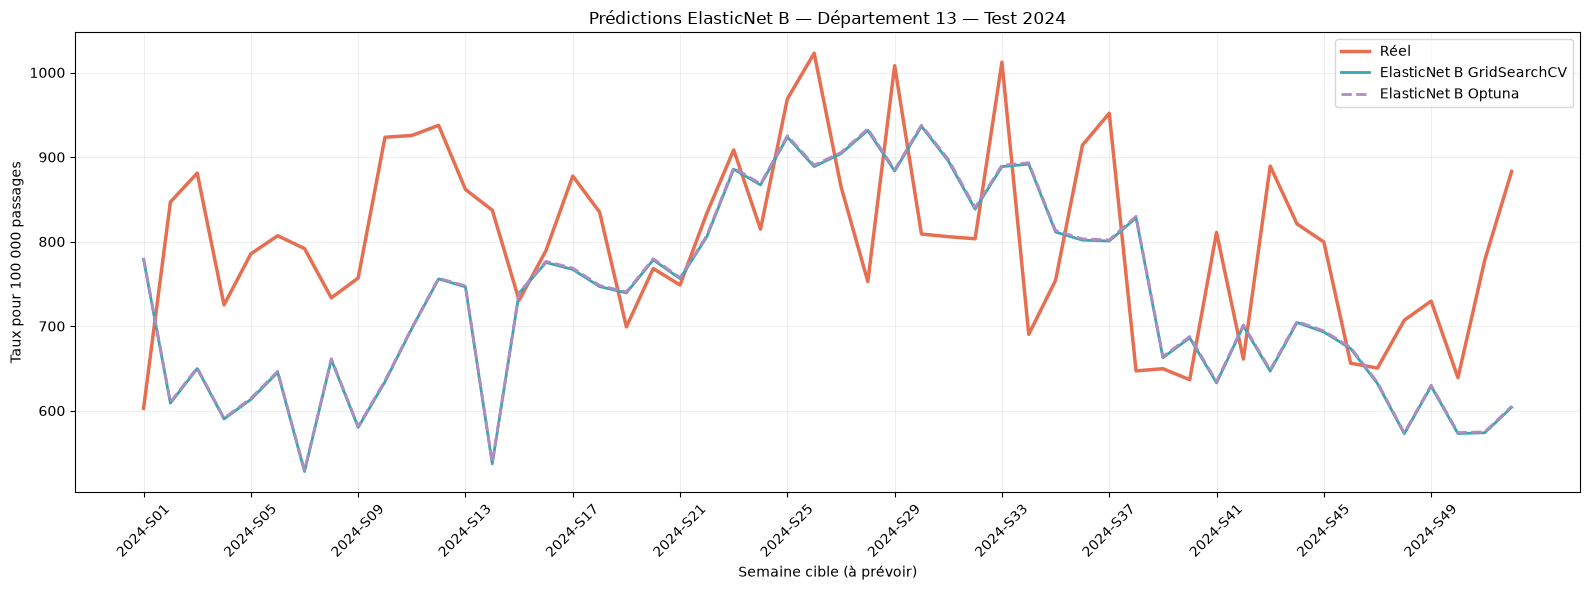

In [84]:
# Comparaison réel vs prédictions sur test
dept = "13"

# Regrouper les prédictions
comparaison = test[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Réel"] = y_test
comparaison["GridSearchCV"] = prediction_B_opt_test
comparaison["Optuna"] = prediction_B_optuna_test

# Filtrer et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")

# Graphique
plt.figure(figsize=(16, 6))

plt.plot(courbes["semaine_a_prevoir"], courbes["Réel"],
         label="Réel", color="#E76F51", linewidth=2.5)

plt.plot(courbes["semaine_a_prevoir"], courbes["GridSearchCV"],
         label="ElasticNet B GridSearchCV",
         color="#39A5AC", linewidth=2)

plt.plot(courbes["semaine_a_prevoir"], courbes["Optuna"],
         label="ElasticNet B Optuna",
         color="#B08CC5", linewidth=2, linestyle="--")

# Mise en forme
plt.title(f"Prédictions ElasticNet B — Département {dept} — Test 2024")
plt.ylabel("Taux pour 100 000 passages")
plt.xlabel("Semaine cible (à prévoir)")

plt.xticks(courbes["semaine_a_prevoir"].iloc[::4], rotation=45)
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()